# ECON 3P14 – Assignment 2, Question 2 (Python Applications)

## (a) Load the data, set dates as the index, display first five rows

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

df = pd.read_csv("Assignment2Data.csv", parse_dates=["Date"], index_col="Date")
df.columns = ["Consumption", "Income"]   # shorter names (millions of $)
df.head()

,Consumption,Income
Date,,
1961-03-31,193805,26780
1961-06-30,197421,27204
1961-09-30,202241,28060
1961-12-31,203009,28468
1962-03-31,207687,29408


## (b) Levels of income and consumption over time

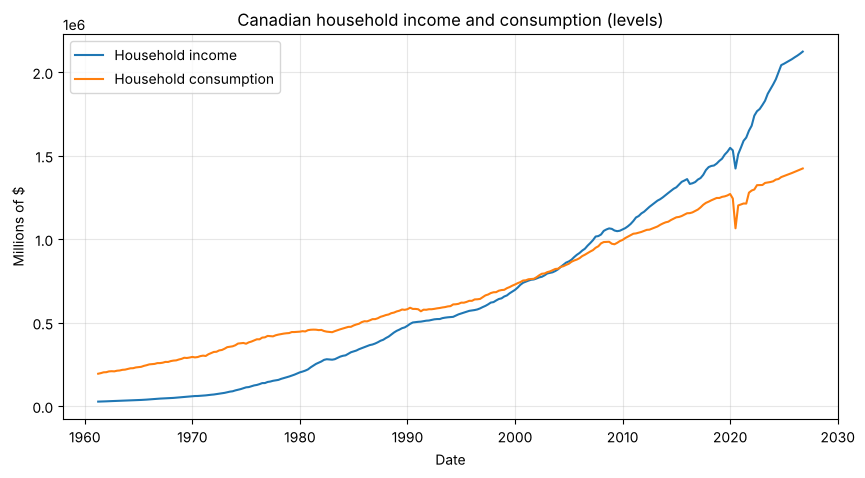

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df.index, df["Income"], label="Household income")
ax.plot(df.index, df["Consumption"], label="Household consumption")
ax.set_title("Canadian household income and consumption (levels)")
ax.set_xlabel("Date"); ax.set_ylabel("Millions of $")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## (c) Quarter-over-quarter percent changes

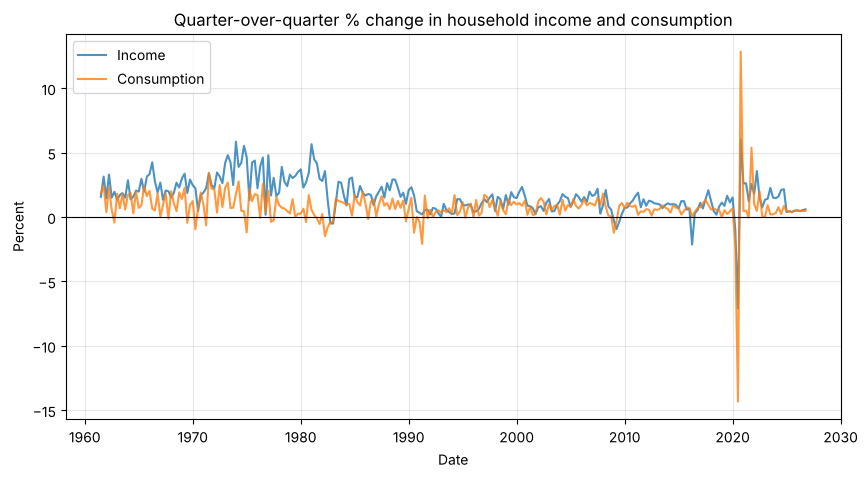

      Consumption  Income
mean        0.775   1.692
std         1.460   1.352
min       -14.329  -7.091
max        12.851   6.035


In [3]:
growth = df.pct_change() * 100          # q/q percent change
growth = growth.dropna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(growth.index, growth["Income"], label="Income", alpha=0.8)
ax.plot(growth.index, growth["Consumption"], label="Consumption", alpha=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Quarter-over-quarter % change in household income and consumption")
ax.set_xlabel("Date"); ax.set_ylabel("Percent")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print(growth.describe().loc[["mean", "std", "min", "max"]].round(3))

In [4]:
# Volatility (std. dev. of q/q % changes): full sample vs. excluding the COVID-19 period
covid = (growth.index >= "2020-01-01") & (growth.index <= "2021-12-31")
print("Full sample:\n", growth.std().round(3), "\n")
print("Excluding 2020-2021:\n", growth[~covid].std().round(3))

Full sample:
 Consumption    1.460
Income         1.352
dtype: float64 

Excluding 2020-2021:
 Consumption    0.774
Income         1.212
dtype: float64


**Answer:** Visually, in most of the sample consumption growth fluctuates in a narrower band than income growth, i.e. consumption appears **less volatile** than income. This is consistent with consumption smoothing. The exception is the COVID-19 period (2020), when consumption growth swings very sharply (about −14.3% in 2020Q2 and +12.9% in 2020Q3, versus −7.1% and +6.0% for income) because lockdowns directly restricted spending while government transfers supported income. These swings dominate the full-sample picture: the full-sample standard deviation is slightly higher for consumption (1.46) than for income (1.35), but excluding 2020–2021 it is much lower for consumption (0.77 vs. 1.21).

## (d) Regression of consumption growth on income growth

In [5]:
X = sm.add_constant(growth["Income"])
model = sm.OLS(growth["Consumption"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            Consumption   R-squared:                       0.248
Model:                            OLS   Adj. R-squared:                  0.246
Method:                 Least Squares   F-statistic:                     85.95
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           7.34e-18
Time:                        16:13:09   Log-Likelihood:                -432.98
No. Observations:                 262   AIC:                             870.0
Df Residuals:                     260   BIC:                             877.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1359      0.126     -1.082      0.2

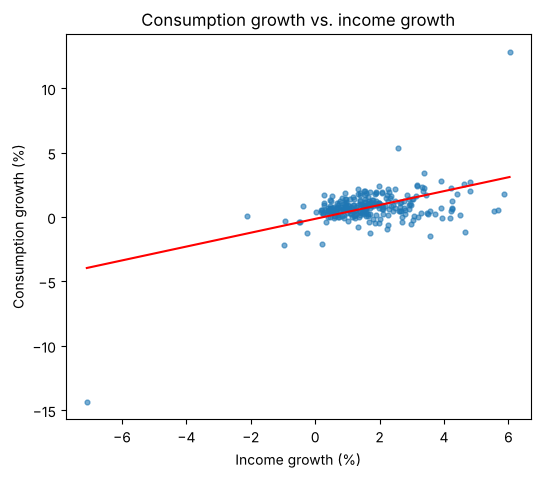

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(growth["Income"], growth["Consumption"], s=12, alpha=0.6)
xs = np.linspace(growth["Income"].min(), growth["Income"].max(), 100)
ax.plot(xs, model.params["const"] + model.params["Income"] * xs, color="red")
ax.set_xlabel("Income growth (%)"); ax.set_ylabel("Consumption growth (%)")
ax.set_title("Consumption growth vs. income growth")
plt.show()

In [7]:
# Robustness check: exclude the COVID-19 period (2020-2021)
g2 = growth[~covid]
model2 = sm.OLS(g2["Consumption"], sm.add_constant(g2["Income"])).fit()
print("Slope (excl. 2020-21): %.3f  (std. err. %.3f), R-squared %.3f" % (model2.params["Income"], model2.bse["Income"], model2.rsquared))

Slope (excl. 2020-21): 0.161  (std. err. 0.039), R-squared 0.064


**Answer:** The estimated slope is **0.54** (standard error 0.058, t = 9.3, p < 0.001; 95% confidence interval roughly [0.42, 0.65]). 

- **Direction:** the slope is positive, so consumption moves in the **same direction** as income: a 1 percentage point increase in household income growth is associated with about a 0.54 percentage point increase in consumption growth.
- **Size:** the effect is **smaller** than one-for-one. The confidence interval excludes 1, so consumption responds significantly less than income. (Excluding the COVID-19 period, the slope is even smaller, about 0.16.) The R² of 0.25 shows that income growth explains only a limited part of consumption growth.
- **Link to the two-period model:** these findings are consistent with the model. When current income rises, lifetime wealth rises, so both current and future consumption increase (consumption moves in the same direction), but the consumer spreads the extra income over both periods using saving, so current consumption rises by **less than** the increase in income (consumption smoothing; marginal propensity to consume out of current income between 0 and 1). A slope of 1 would mean no smoothing, and a slope of 0 would mean that consumption ignores current income entirely. The model does best for temporary income changes; the slope is not zero because some income changes are permanent (they raise lifetime wealth by more, so consumption responds more) and because some households face credit constraints and cannot smooth fully.
- **Caveats:** the income series is nominal while consumption is in constant 2017 dollars, which is why average income growth is higher than consumption growth (reflected in the negative intercept), and the quarterly data cannot separate permanent from transitory income changes.